In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

DATA_PATH = Path("../data/processed/mexico-real-estate-clean.csv")

df = pd.read_csv(DATA_PATH)

print(df.shape)
df.head()

(1736, 6)


,property_type,state,lat,lon,area_m2,price_usd
0,house,Estado de México,19.560181,-99.233528,150.0,67965.56
1,house,Nuevo León,25.688436,-100.198807,186.0,63223.78
2,apartment,Guerrero,16.767704,-99.764383,82.0,84298.37
3,apartment,Guerrero,16.829782,-99.911012,150.0,94308.80
4,house,Yucatán,21.052583,-89.538639,205.0,105191.37


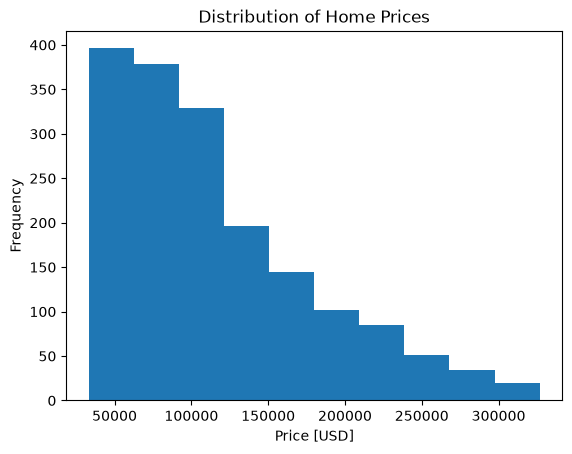

In [2]:
fig, ax = plt.subplots()

ax.hist(df["price_usd"], bins=10)
ax.set_xlabel("Price [USD]")
ax.set_ylabel("Frequency")
ax.set_title("Distribution of Home Prices");

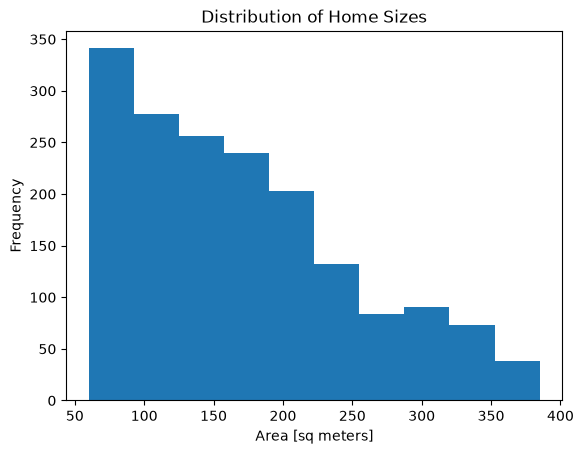

In [3]:
fig, ax = plt.subplots()

ax.hist(df["area_m2"], bins=10)
ax.set_xlabel("Area [sq meters]")
ax.set_ylabel("Frequency")
ax.set_title("Distribution of Home Sizes");

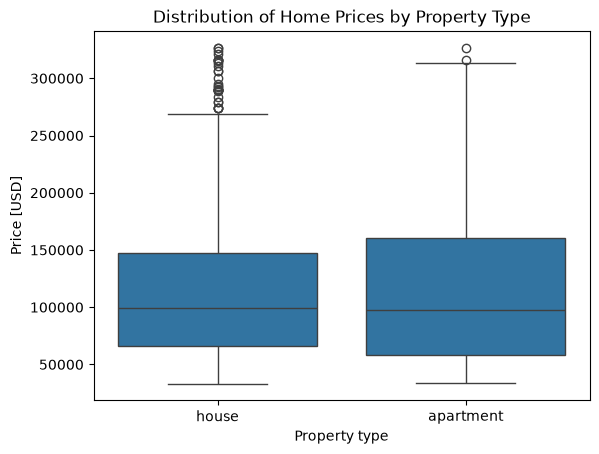

In [4]:
fig, ax = plt.subplots()

sns.boxplot(x="property_type", y="price_usd", data=df, ax=ax)
ax.set_xlabel("Property type")
ax.set_ylabel("Price [USD]")
ax.set_title("Distribution of Home Prices by Property Type");

state
Distrito Federal    303
Estado de México    179
Yucatán             171
Name: count, dtype: int64


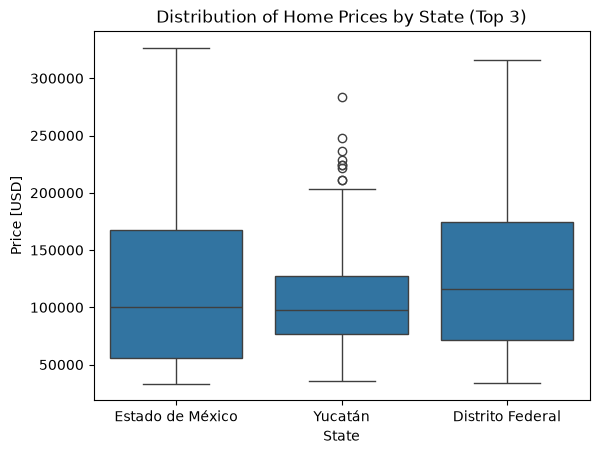

In [5]:
top_states = df["state"].value_counts().head(3)
print(top_states)

df_top3 = df[df["state"].isin(top_states.index)]

fig, ax = plt.subplots()

sns.boxplot(x="state", y="price_usd", data=df_top3, ax=ax)
ax.set_xlabel("State")
ax.set_ylabel("Price [USD]")
ax.set_title("Distribution of Home Prices by State (Top 3)");

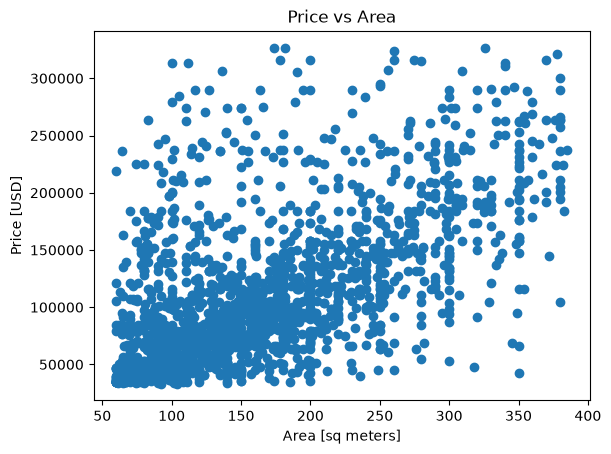

In [6]:
fig, ax = plt.subplots()

ax.scatter(x=df["area_m2"], y=df["price_usd"])
ax.set_xlabel("Area [sq meters]")
ax.set_ylabel("Price [USD]")
ax.set_title("Price vs Area");

In [7]:
price_low = df["price_usd"].quantile(0.05)
price_high = df["price_usd"].quantile(0.90)
area_high = df["area_m2"].quantile(0.90)

print("Price 5th percentile:", price_low)
print("Price 90th percentile:", price_high)
print("Area 90th percentile:", area_high)

mask = (
    (df["price_usd"] >= price_low)
    & (df["price_usd"] <= price_high)
    & (df["area_m2"] <= area_high)
)

df_filtered = df[mask]

print("Rows before:", len(df))
print("Rows after:", len(df_filtered))

Price 5th percentile: 39232.060000000005
Price 90th percentile: 210795.91
Area 90th percentile: 298.0
Rows before: 1736
Rows after: 1371


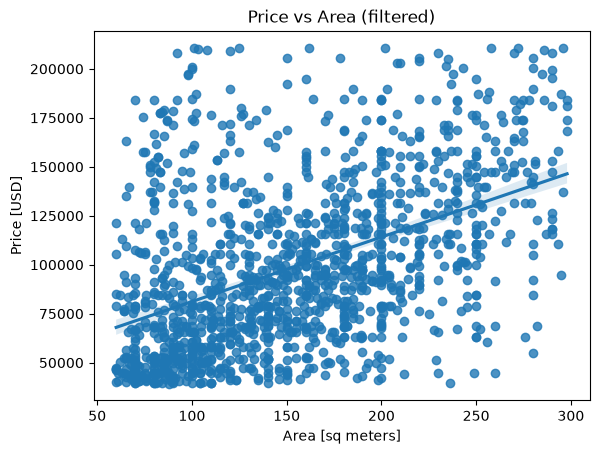

In [8]:
fig, ax = plt.subplots()

sns.regplot(x="area_m2", y="price_usd", data=df_filtered, ax=ax)
ax.set_xlabel("Area [sq meters]")
ax.set_ylabel("Price [USD]")
ax.set_title("Price vs Area (filtered)");

state
Querétaro           133955.913417
Guanajuato          133277.965833
Nuevo León          129221.985834
Distrito Federal    128347.267365
Quintana Roo        128065.415734
Name: price_usd, dtype: float64


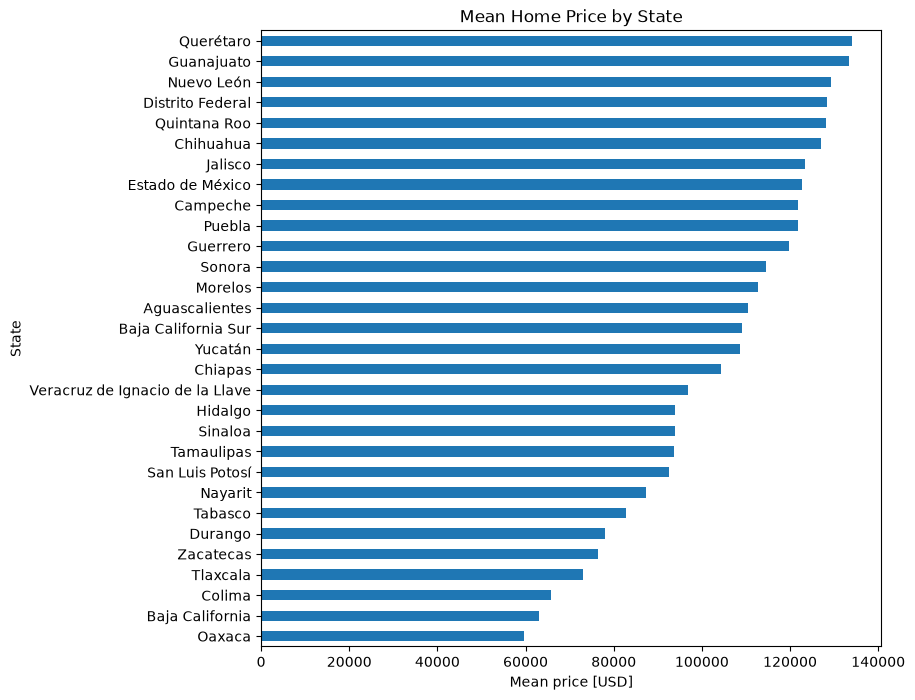

In [9]:
mean_price_by_state = (
    df.groupby("state")["price_usd"]
    .mean()
    .sort_values(ascending=False)
)

print(mean_price_by_state.head())

fig, ax = plt.subplots(figsize=(8, 8))

mean_price_by_state.plot(kind="barh", ax=ax)
ax.invert_yaxis()
ax.set_xlabel("Mean price [USD]")
ax.set_ylabel("State")
ax.set_title("Mean Home Price by State");

## Findings log (Lesson 1.2)

**Distributions**
- Price and area are both right-skewed (price more steeply). Largest listing is 385 m², so the lesson's description of much larger homes does not apply to my data.

**Decisions**
- Top 3 states by listings: Distrito Federal (303), Estado de México (179), Yucatán (171), 653 rows. "Distrito Federal" is the older name for Mexico City.
- Quantile filter, for visualisation only: price between the 5th ($39,232) and 90th ($210,796) percentiles, area up to the 90th (298 m²). 1,736 → 1,371 rows (21% dropped). `df` is unchanged; results from the filtered plots describe the middle of the market only.

**Observations**
- Property type: house and apartment medians are almost equal (about $98-99k).
- State: medians and spread differ across the top 3 states.
- Price vs area: weak-to-moderate positive trend (about $325 per m² read off the plot), with a wide cloud around the line. Many listings share round area values, which creates vertical stripes.
- Mean price by state ranges from about $59k (Oaxaca) to $134k (Querétaro). Some states have few listings, so their means are less reliable.

In [10]:
counts = df["state"].value_counts()
print(counts[["Querétaro", "Guanajuato", "Oaxaca", "Baja California", "Colima"]])

state
Querétaro          128
Guanajuato          12
Oaxaca               2
Baja California     29
Colima               5
Name: count, dtype: int64


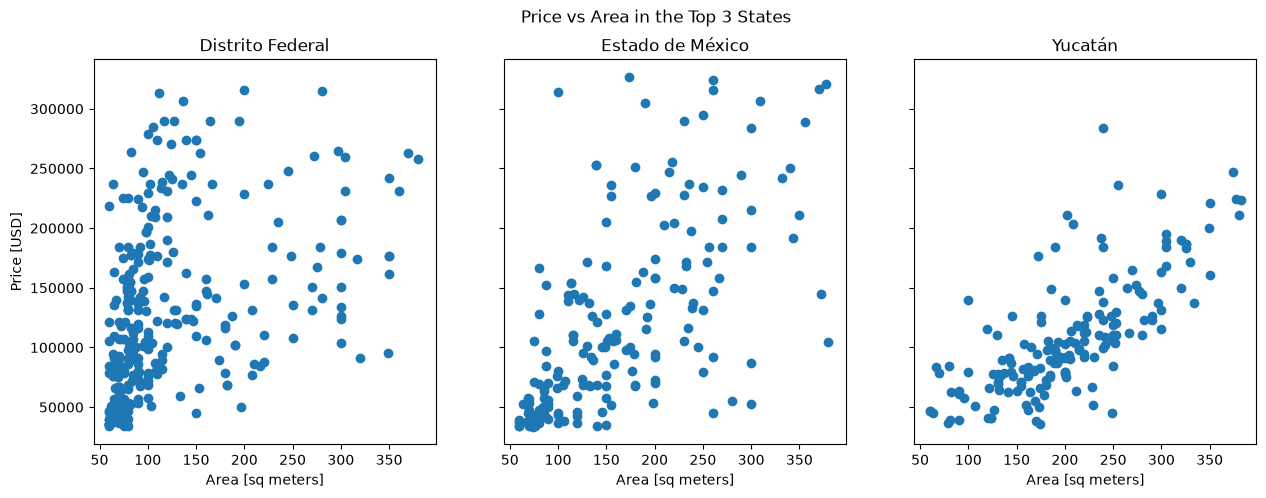

In [11]:
fig, axes = plt.subplots(
    nrows=1, ncols=3, figsize=(15, 5), sharey=True, sharex=True
)

for ax, state in zip(axes, top_states.index):
    subset = df_top3[df_top3["state"] == state]
    ax.scatter(x=subset["area_m2"], y=subset["price_usd"])
    ax.set_title(state)
    ax.set_xlabel("Area [sq meters]")

axes[0].set_ylabel("Price [USD]")
fig.suptitle("Price vs Area in the Top 3 States");

**Observations: price vs area in the top 3 states**
- The price-vs-area relationship differs by state: strong in Yucatán, moderate in Estado de México, weak in Distrito Federal.
- Location affects both the price level and how much size matters.
- Caveats: only three states, plotted from the full `df` (no quantile filter), and judged by eye. Nothing has been measured numerically yet.